# **Практическая работа №1. Основные методы OpenCV. Часть №1**

---

# **Тема №1. Чтение, запись и отображение**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import requests
from io import BytesIO



## **Задание 1:**  
Напишите процедуру, которая:

- Считывает цветное изображение в режиме `cv2.IMREAD_COLOR`.
- Преобразует его в оттенки серого с использованием `cv2.cvtColor()`.
- Сохраняет полученное черно-белое изображение на диск.
- Отображает оба изображения (оригинальное цветное и преобразованное черно-белое).




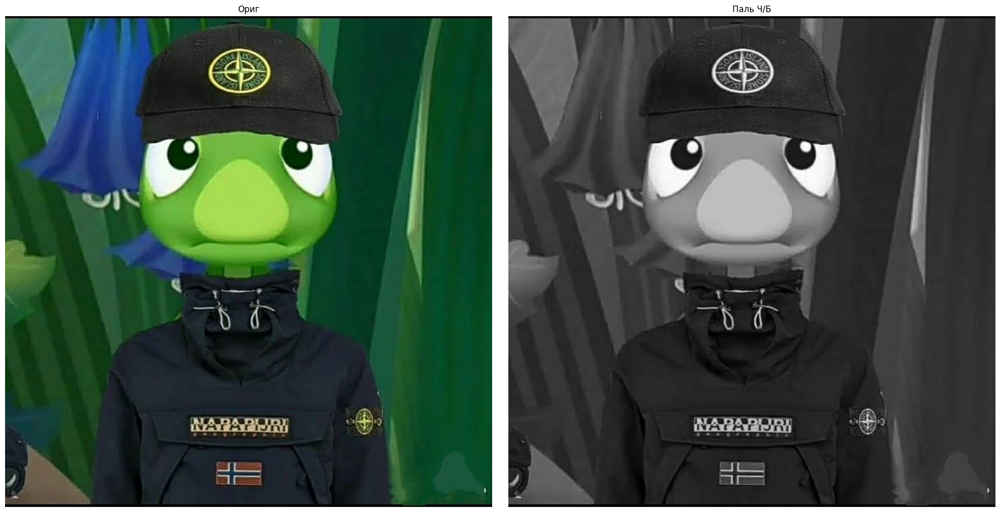

In [9]:

def task_1(url):
    resp = requests.get(url, stream=True).raw
    img = np.asarray(bytearray(resp.read()), dtype='uint8')
    img = cv2.imdecode(img, cv2.IMREAD_COLOR)
    dst = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    cv2.imwrite('dst_task_1.jpg', dst)
    plt.figure(figsize=(20, 10))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title('Ориг')
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(dst, cmap='gray')
    plt.title('Паль Ч/Б')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

URL = r'https://i.pinimg.com/736x/ab/39/6d/ab396d7b1c7e3391ca17ecfd4e39bf3e.jpg'
task_1(URL)

## **Задание 2:**  
Используя режим `cv2.IMREAD_UNCHANGED`, загрузите изображение с альфа-каналом (например, PNG с прозрачностью). Затем:

- Разделите изображение на каналы (B, G, R, A).
- Создайте новое изображение, где прозрачность (альфа-канал) инвертирована (т.е. прозрачные области становятся непрозрачными и наоборот).
- Сохраните и отобразите полученное изображение.

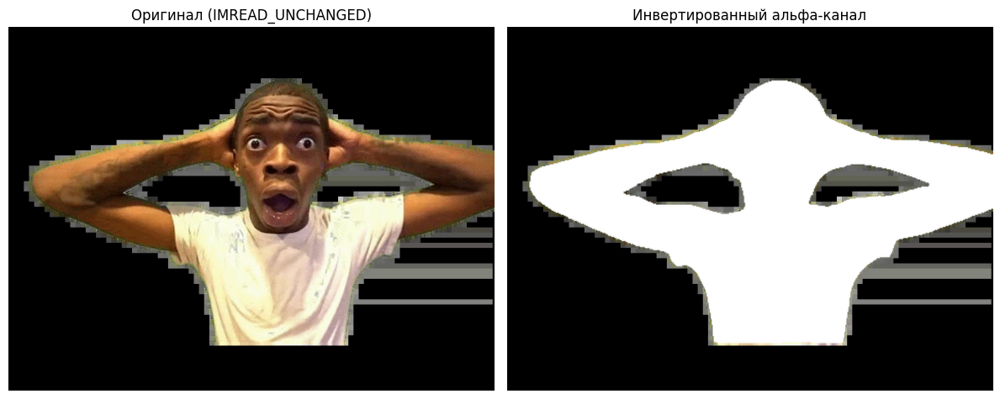

In [33]:
def task_2(image_url):
    http_response = requests.get(image_url, stream=True).raw
    raw_data = np.asarray(bytearray(http_response.read()), dtype='uint8')
    loaded_image = cv2.imdecode(raw_data, cv2.IMREAD_UNCHANGED)
    blue_channel, green_channel, red_channel, alpha_channel = cv2.split(loaded_image)
    inv_alpha = cv2.bitwise_not(alpha_channel)
    processed_image = cv2.merge([blue_channel, green_channel, red_channel, inv_alpha])
    cv2.imwrite('dst_task_2.png', processed_image)
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(loaded_image, cv2.COLOR_BGR2RGB))
    plt.title('Оригинал (IMREAD_UNCHANGED)')
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(processed_image, cv2.COLOR_BGR2RGBA))
    plt.title('Инвертированный альфа-канал')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

URL_PNG = r'https://static.wikia.nocookie.net/36cbde92-5cb0-4556-9b53-bdf699574b72/scale-to-width/755'
task_2(URL_PNG)

---

# **Тема №2. Работа с цветовыми палитрами**



## **Задание 3:**  
Напишите процедуру, которая:

- Считывает цветное изображение.
- Преобразует его из цветового пространства BGR в HSV с помощью `cv2.cvtColor()`.
- Увеличивает насыщенность (канал S) в 1.5 раза, не превышая максимального значения.
- Преобразует изображение обратно в цветовое пространство BGR.
- Отображает оригинальное и полученное изображения рядом для сравнения.

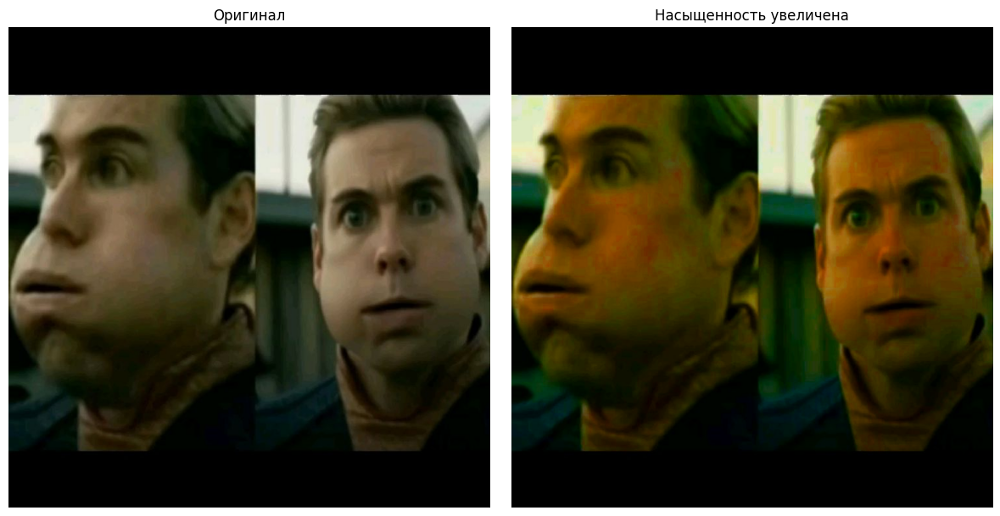

In [37]:
def number_3(image_url, saturation_factor=1.5):
    http_response = requests.get(image_url, stream=True).raw
    raw_bytes = np.asarray(bytearray(http_response.read()), dtype='uint8')
    original_bgr = cv2.imdecode(raw_bytes, cv2.IMREAD_COLOR)
    hsv_space = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2HSV)
    hue_ch, sat_ch, val_ch = cv2.split(hsv_space)
    sat_ch = cv2.multiply(sat_ch, saturation_factor)
    sat_ch = np.clip(sat_ch, 0, 255).astype(np.uint8)
    hsv_space = cv2.merge([hue_ch, sat_ch, val_ch])
    result_bgr = cv2.cvtColor(hsv_space, cv2.COLOR_HSV2BGR)
    cv2.imwrite('dst_task_3.jpg', result_bgr)
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB))
    plt.title('Оригинал')
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(result_bgr, cv2.COLOR_BGR2RGB))
    plt.title(f'Насыщенность увеличена')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

URL = r'https://i.pinimg.com/736x/1c/f3/09/1cf3094a2c0487cd230007fe2889bc0c.jpg'
number_3(URL, saturation_factor=3)

## **Задание 4:**  
Напишите процедуру, которая:

- Считывает изображение и Преобразует его в цветовое пространство YCrCb.
- Применяет размытие к компоненте яркости Y (при помощи фильтра, см. материал предыдущих занятий).
- Снова Преобразует изображение в цветовое пространство BGR.
- Отображает исходное и размытое изображения.

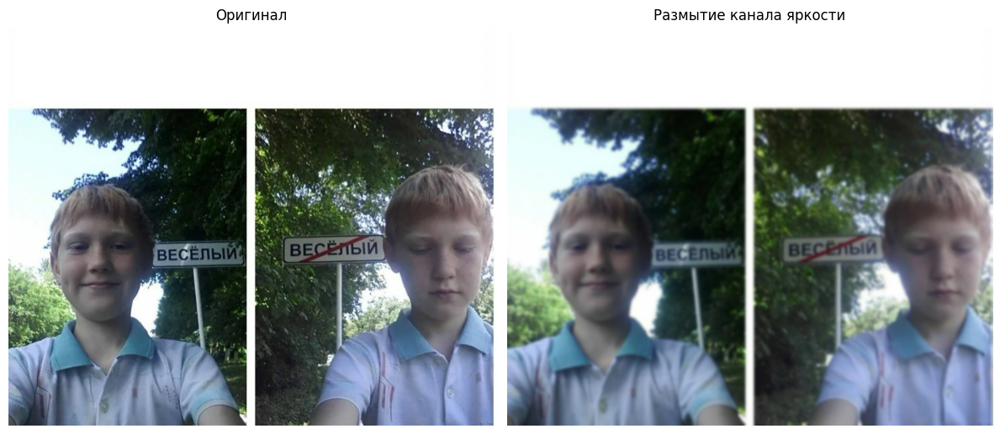

In [42]:
def num_4(image_url):
    http_stream = requests.get(image_url, stream=True).raw
    byte_array = np.asarray(bytearray(http_stream.read()), dtype='uint8')
    source_bgr = cv2.imdecode(byte_array, cv2.IMREAD_COLOR)
    source_rgb = cv2.cvtColor(source_bgr, cv2.COLOR_BGR2RGB)
    ycrcb_space = cv2.cvtColor(source_bgr, cv2.COLOR_BGR2YCrCb)
    y_channel, cr_channel, cb_channel = cv2.split(ycrcb_space)
    y_channel = cv2.GaussianBlur(y_channel, (15, 15), 0)
    ycrcb_space = cv2.merge([y_channel, cr_channel, cb_channel])
    processed_result = cv2.cvtColor(ycrcb_space, cv2.COLOR_YCrCb2RGB)
    cv2.imwrite('dst_task_4.jpg', cv2.cvtColor(processed_result, cv2.COLOR_RGB2BGR))
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(source_rgb)
    plt.title('Оригинал')
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(processed_result)
    plt.title('Размытие канала яркости')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

URL = r'https://avatars.mds.yandex.net/i?id=8e81171dad6dbe6ab06ed87050979ac9_l-5883298-images-thumbs&n=13'
num_4(URL)

---

# **Тема №3. Слияние и усиление**

## **Задание 5:**  
Создайте процедуру, которая:

- Считывает два изображения одинакового размера (можно подкорректировать с помощью метода `.resize()`).
- Выполняет побитовое ИЛИ (OR) над соответствующими пикселями двух изображений.
- Сохраняет и отображает результат операции.

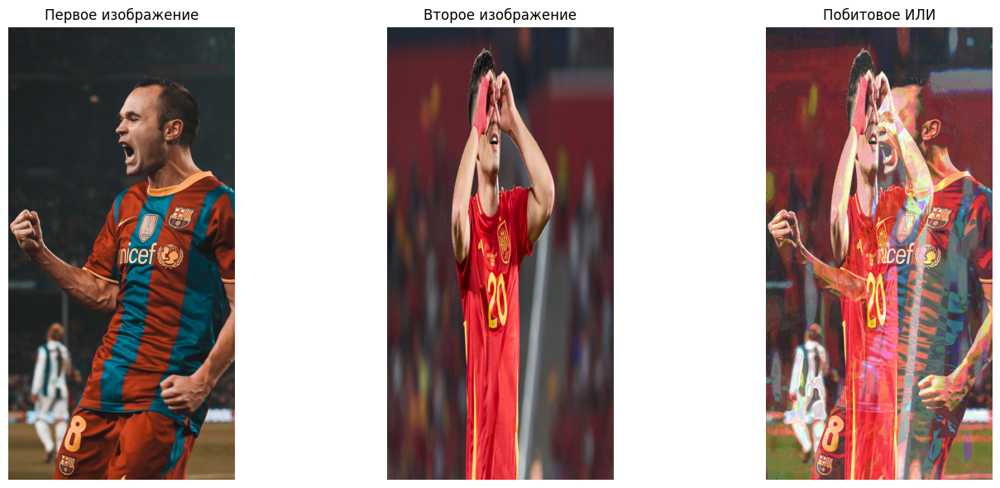

In [45]:
def task_5(first_image_link, second_image_link):
    stream_response_one = requests.get(first_image_link, stream=True).raw
    raw_data_one = np.asarray(bytearray(stream_response_one.read()), dtype='uint8')
    image_matrix_first = cv2.imdecode(raw_data_one, cv2.IMREAD_COLOR)
    height, width = image_matrix_first.shape[:2]
    stream_response_two = requests.get(second_image_link, stream=True).raw
    raw_data_two = np.asarray(bytearray(stream_response_two.read()), dtype='uint8')
    image_matrix_second = cv2.imdecode(raw_data_two, cv2.IMREAD_COLOR)
    image_matrix_second = cv2.resize(image_matrix_second, (width, height))
    bitwise_result_image = cv2.bitwise_or(image_matrix_first, image_matrix_second)
    cv2.imwrite('dst_task_5.jpg', bitwise_result_image)
    plt.figure(figsize=(15, 6))
    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(image_matrix_first, cv2.COLOR_BGR2RGB))
    plt.title('Первое изображение')
    plt.axis('off')
    plt.subplot(1, 3, 2)
    plt.imshow(cv2.cvtColor(image_matrix_second, cv2.COLOR_BGR2RGB))
    plt.title('Второе изображение')
    plt.axis('off')
    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(bitwise_result_image, cv2.COLOR_BGR2RGB))
    plt.title('Побитовое ИЛИ')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

URL1 = 'https://i.pinimg.com/originals/0b/e3/d1/0be3d1a2ac48874f92773cfe09c8042b.jpg'
URL2 = 'https://s-cdn.sportbox.ru/images/styles/upload/fp_fotos/96/db/5843d6a9552bed2053e61495bd215f456664d2025860e429598463.jpg'
task_5(URL1, URL2)

## **Задание 6:**  
Реализуйте следующий алгоритм:

- Считайте цветное изображение и разделите его на три канала с использованием `.split()`.
- Примените к каждому каналу разный коэффициент гамма-коррекции (например, для R – 0.5, G – 1.0, B – 1.5).
- Объедините каналы обратно с помощью `.merge()`.
- Отобразите исходное и обработанное изображения.


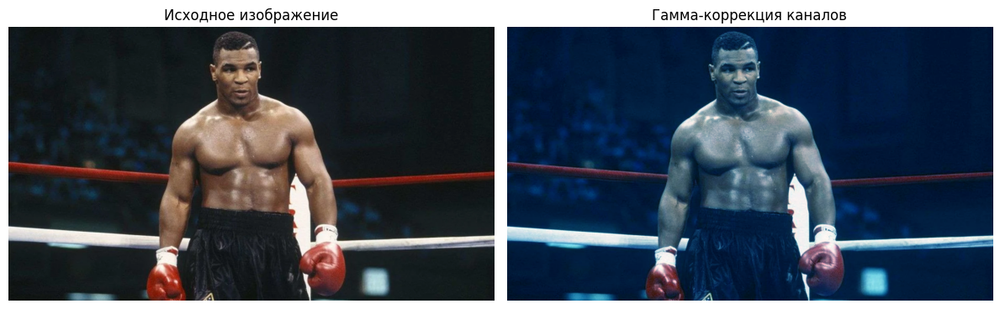

In [46]:
def apply_gamma_correction(img_channel, gamma_value):
    inv_gamma_val = 1.0 / gamma_value
    gamma_table = np.array([((pixel_val / 255.0) ** inv_gamma_val) * 255 for pixel_val in np.arange(0, 256)]).astype(np.uint8)
    return cv2.LUT(img_channel, gamma_table)

def process_channels_gamma(image_link):
    http_stream = requests.get(image_link, stream=True).raw
    byte_data = np.asarray(bytearray(http_stream.read()), dtype='uint8')
    source_bgr_matrix = cv2.imdecode(byte_data, cv2.IMREAD_COLOR)
    blue_ch, green_ch, red_ch = cv2.split(source_bgr_matrix)
    blue_ch = apply_gamma_correction(blue_ch, 1.5)
    green_ch = apply_gamma_correction(green_ch, 1.0)
    red_ch = apply_gamma_correction(red_ch, 0.5)
    merged_bgr_result = cv2.merge([blue_ch, green_ch, red_ch])
    cv2.imwrite('dst_task_6.jpg', merged_bgr_result)
    original_rgb_view = cv2.cvtColor(source_bgr_matrix, cv2.COLOR_BGR2RGB)
    processed_rgb_view = cv2.cvtColor(merged_bgr_result, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(original_rgb_view)
    plt.title('Исходное изображение')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(processed_rgb_view)
    plt.title('Гамма-коррекция каналов')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

IMAGE_LINK = 'https://photobooth.cdn.sports.ru/preset/post/2/92/4dafc8019437688a27122994923bd.jpeg?f=webp&q=90&s=2x&w=730'
process_channels_gamma(IMAGE_LINK)

---

# **Тема №4. Работа с гистограммами в OpenCV**

## **Задание 7:**  
Напишите процедуру для улучшения контрастности изображения:

- Считывает изображение в оттенках серого.
- Строит его гистограмму с использованием `cv.calcHist()`.
- Применяет эквализацию гистограммы методом `cv2.equalizeHist()`.
- Отображает на одном графике исходное и эквализованное изображения вместе с их гистограммами.

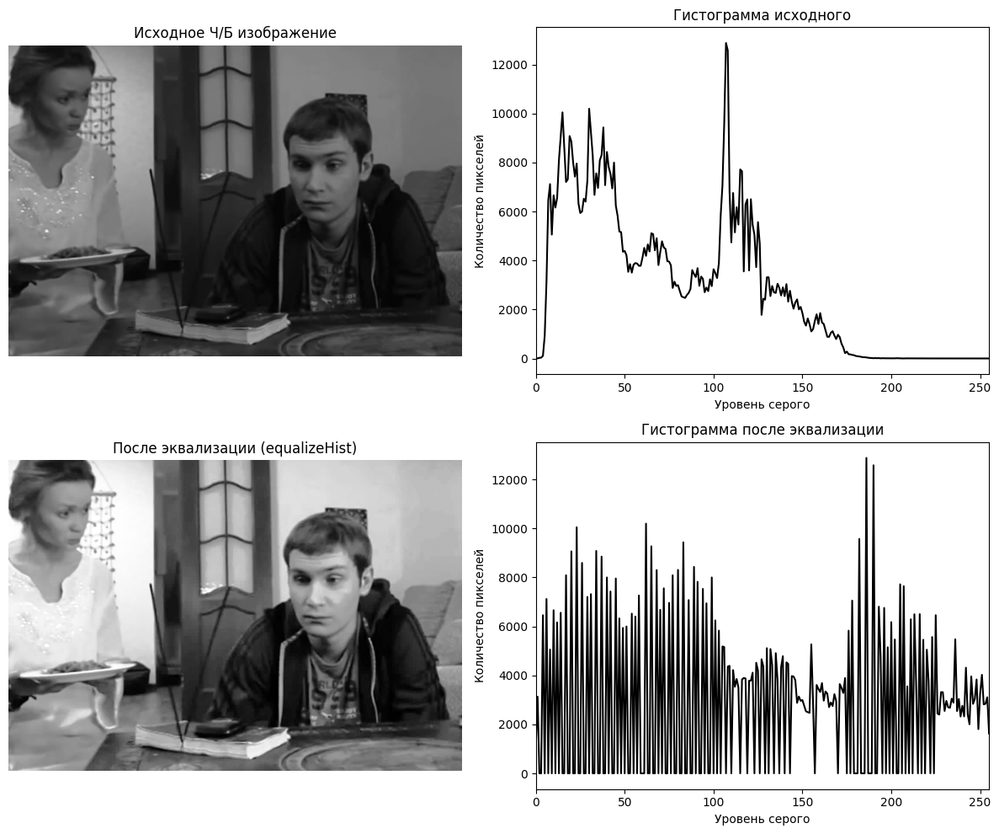

In [47]:
def enhance_contrast_histogram(image_source_url):
    network_response = requests.get(image_source_url, stream=True).raw
    byte_array_data = np.asarray(bytearray(network_response.read()), dtype='uint8')
    loaded_color_image = cv2.imdecode(byte_array_data, cv2.IMREAD_COLOR)
    grayscale_source_image = cv2.cvtColor(loaded_color_image, cv2.COLOR_BGR2GRAY)
    original_histogram_data = cv2.calcHist([grayscale_source_image], [0], None, [256], [0, 256])
    equalized_contrast_image = cv2.equalizeHist(grayscale_source_image)
    equalized_histogram_data = cv2.calcHist([equalized_contrast_image], [0], None, [256], [0, 256])
    cv2.imwrite('dst_task_7.jpg', equalized_contrast_image)
    plt.figure(figsize=(12, 10))
    plt.subplot(2, 2, 1)
    plt.imshow(grayscale_source_image, cmap='gray')
    plt.title('Исходное Ч/Б изображение')
    plt.axis('off')
    plt.subplot(2, 2, 2)
    plt.plot(original_histogram_data, color='black')
    plt.xlim([0, 255])
    plt.title('Гистограмма исходного')
    plt.xlabel('Уровень серого')
    plt.ylabel('Количество пикселей')
    plt.subplot(2, 2, 3)
    plt.imshow(equalized_contrast_image, cmap='gray')
    plt.title('После эквализации (equalizeHist)')
    plt.axis('off')
    plt.subplot(2, 2, 4)
    plt.plot(equalized_histogram_data, color='black')
    plt.xlim([0, 255])
    plt.title('Гистограмма после эквализации')
    plt.xlabel('Уровень серого')
    plt.ylabel('Количество пикселей')

    plt.tight_layout()
    plt.show()

NEW_URL = 'https://iv.okcdn.ru/getVideoPreview?id=7276570610214&idx=1&type=39&tkn=Mb7wzHhPP6s8sex8tu2vLLD7FkI&fn=vid_w'
enhance_contrast_histogram(NEW_URL)

## **Задание 8:**  
Используйте метод CLAHE для улучшения деталей в затемненных областях цветного изображения:

- Преобразуйте изображение из BGR в LAB цветовое пространство.
- Разделите изображение на каналы и примените `cv2.createCLAHE()` к каналу яркости L.
- Объедините обработанный канал L с исходными каналами A и B.
- Преобразуйте изображение обратно в BGR.
- Отобразите исходное и обработанное изображения для сравнения вместе с их гистограммами.

Среднее значение канала Y (Яркость): 44.83
Минимальное значение: 0
Максимальное значение: 245


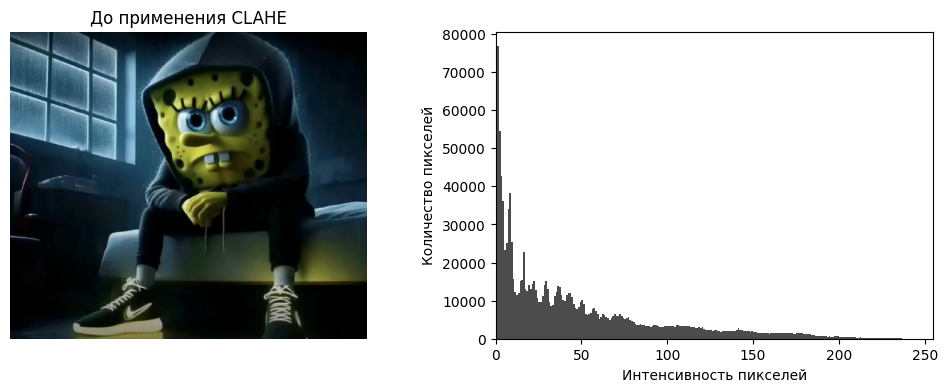

Среднее значение канала Y (Яркость): 63.78
Минимальное значение: 0
Максимальное значение: 252


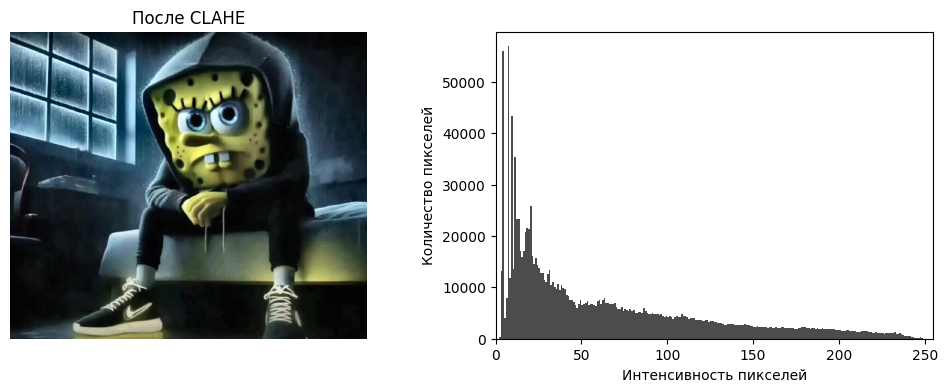

In [50]:
def display_image_with_histogram(source_image, header_title, print_stats=True):
    if source_image.ndim == 3:
        intensity_values = cv2.cvtColor(source_image, cv2.COLOR_BGR2YCrCb)[:, :, 0]
        channel_identifier = "Y (Яркость)"
    else:
        intensity_values = source_image
        channel_identifier = "уровня серого"
    if print_stats:
        print(f"Среднее значение канала {channel_identifier}: {intensity_values.mean():.2f}")
        print(f"Минимальное значение: {intensity_values.min()}")
        print(f"Максимальное значение: {intensity_values.max()}")

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(source_image, cv2.COLOR_BGR2RGB))
    plt.title(header_title)
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.hist(intensity_values.ravel(), bins=256, range=(0, 256), color='black', alpha=0.7)
    plt.xlim([0, 255])
    plt.xlabel("Интенсивность пикселей")
    plt.ylabel("Количество пикселей")
    plt.tight_layout()
    plt.show()

IMAGE_LINK = 'https://avatars.mds.yandex.net/i?id=4d310d65ab1e2951853f7ce04ca967b3_l-5284124-images-thumbs&n=13'
http_connection = requests.get(IMAGE_LINK, stream=True).raw
byte_stream_data = np.asarray(bytearray(http_connection.read()), dtype='uint8')
decoded_bgr_picture = cv2.imdecode(byte_stream_data, cv2.IMREAD_COLOR)
lab_color_space = cv2.cvtColor(decoded_bgr_picture, cv2.COLOR_BGR2LAB)
luminance_l, channel_a, channel_b = cv2.split(lab_color_space)
clahe_processor = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced_luminance_l = clahe_processor.apply(luminance_l)
merged_lab_image = cv2.merge([enhanced_luminance_l, channel_a, channel_b])
clahe_enhanced_image = cv2.cvtColor(merged_lab_image, cv2.COLOR_LAB2BGR)
cv2.imwrite('dst_task_8.jpg', clahe_enhanced_image)
display_image_with_histogram(decoded_bgr_picture, header_title='До применения CLAHE')
display_image_with_histogram(clahe_enhanced_image, header_title='После CLAHE')

## **Затем:**  
Исследуйте влияние размера окна (tileGridSize) и порога по сравнению с гистограммой (clipLimit) в методе CLAHE на конечный результат. Попробуйте несколько различных значений и визуализируйте результаты.


Среднее значение канала Y (Яркость): 44.83
Минимальное значение: 0
Максимальное значение: 245


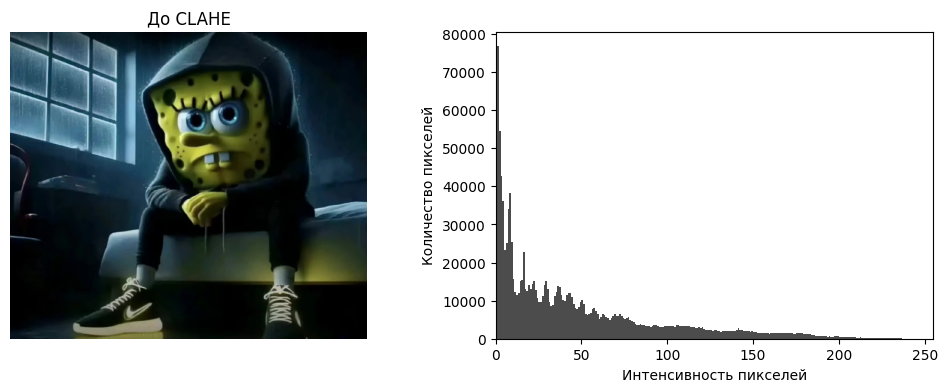

Среднее значение канала Y (Яркость): 69.44
Минимальное значение: 0
Максимальное значение: 252


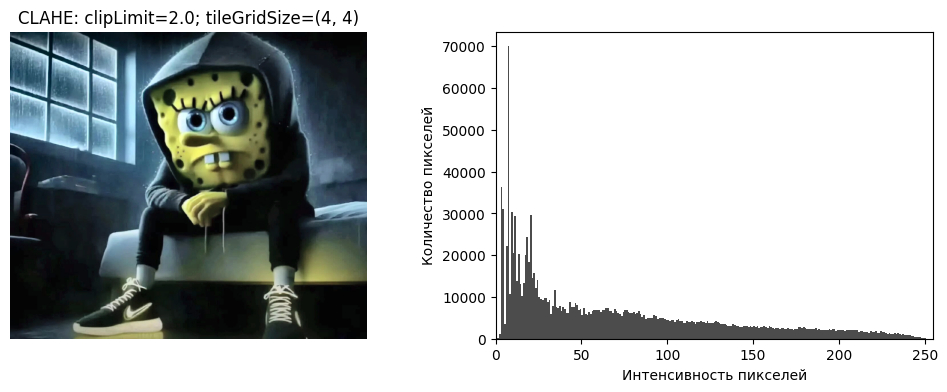

Среднее значение канала Y (Яркость): 63.78
Минимальное значение: 0
Максимальное значение: 252


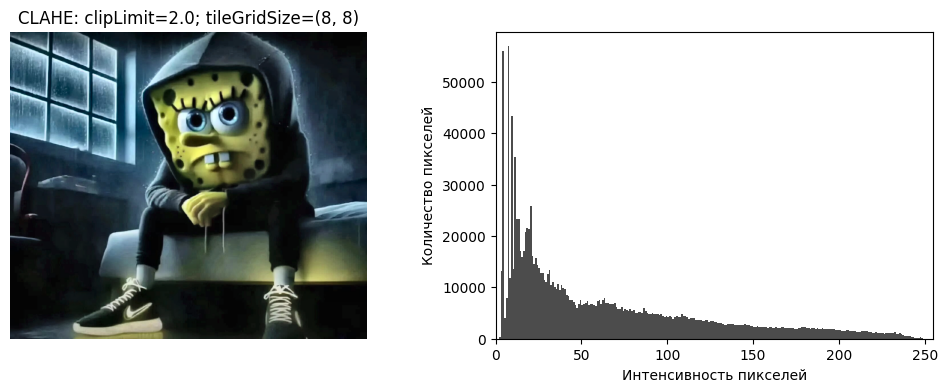

Среднее значение канала Y (Яркость): 59.34
Минимальное значение: 0
Максимальное значение: 252


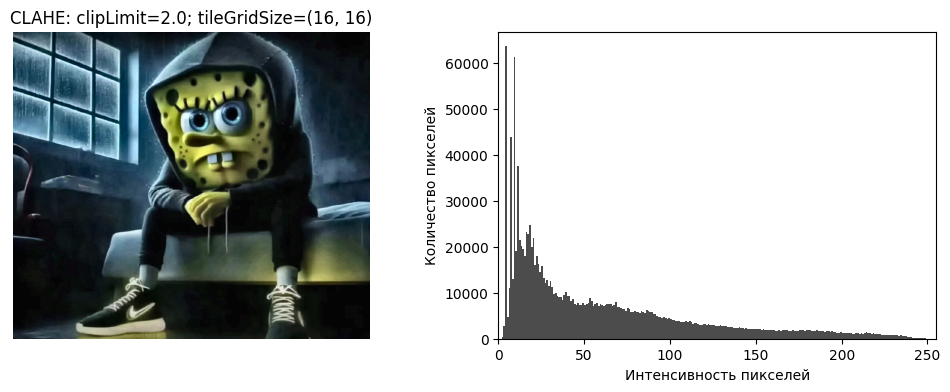

Среднее значение канала Y (Яркость): 54.94
Минимальное значение: 2
Максимальное значение: 248


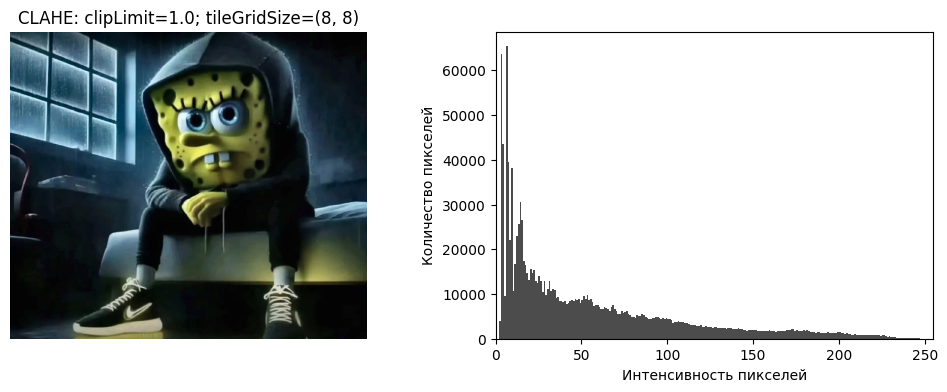

Среднее значение канала Y (Яркость): 75.32
Минимальное значение: 0
Максимальное значение: 252


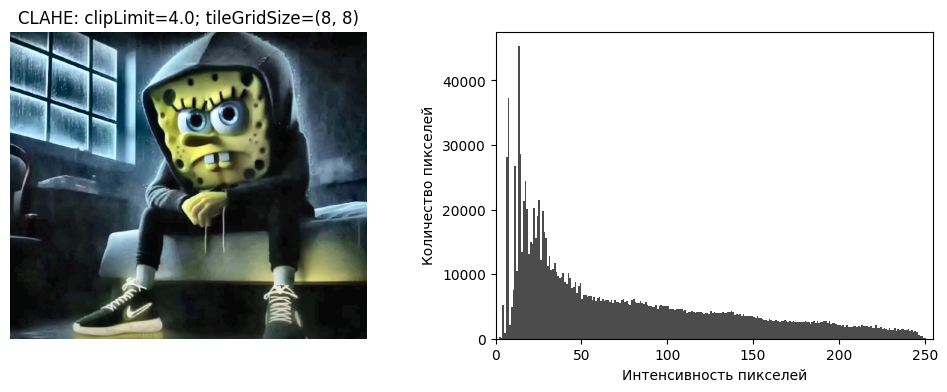

In [52]:

# Новая ссылка на изображение для исследования CLAHE
IMAGE_URL = 'https://avatars.mds.yandex.net/i?id=4d310d65ab1e2951853f7ce04ca967b3_l-5284124-images-thumbs&n=13'

network_stream = requests.get(IMAGE_URL, stream=True).raw
image_bytes_data = np.asarray(bytearray(network_stream.read()), dtype='uint8')
loaded_bgr_picture = cv2.imdecode(image_bytes_data, cv2.IMREAD_COLOR)

# Преобразуем изображение в цветовое пространство LAB
lab_color_matrix = cv2.cvtColor(loaded_bgr_picture, cv2.COLOR_BGR2LAB)

# Отображаем исходное изображение до CLAHE
display_image_with_histogram(loaded_bgr_picture, header_title='До CLAHE')

# clipLimit=2.0; tileGridSize=(4, 4)
l_chan, a_chan, b_chan = cv2.split(lab_color_matrix)
clahe_filter = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
l_chan = clahe_filter.apply(l_chan)
processed_result = cv2.merge([l_chan, a_chan, b_chan])
processed_result = cv2.cvtColor(processed_result, cv2.COLOR_LAB2BGR)
display_image_with_histogram(processed_result, header_title='CLAHE: clipLimit=2.0; tileGridSize=(4, 4)')

# clipLimit=2.0; tileGridSize=(8, 8)
l_chan, a_chan, b_chan = cv2.split(lab_color_matrix)
clahe_filter = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
l_chan = clahe_filter.apply(l_chan)
processed_result = cv2.merge([l_chan, a_chan, b_chan])
processed_result = cv2.cvtColor(processed_result, cv2.COLOR_LAB2BGR)
display_image_with_histogram(processed_result, header_title='CLAHE: clipLimit=2.0; tileGridSize=(8, 8)')

# clipLimit=2.0; tileGridSize=(16, 16)
l_chan, a_chan, b_chan = cv2.split(lab_color_matrix)
clahe_filter = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(16, 16))
l_chan = clahe_filter.apply(l_chan)
processed_result = cv2.merge([l_chan, a_chan, b_chan])
processed_result = cv2.cvtColor(processed_result, cv2.COLOR_LAB2BGR)
display_image_with_histogram(processed_result, header_title='CLAHE: clipLimit=2.0; tileGridSize=(16, 16)')

# clipLimit=1.0; tileGridSize=(8, 8)
l_chan, a_chan, b_chan = cv2.split(lab_color_matrix)
clahe_filter = cv2.createCLAHE(clipLimit=1.0, tileGridSize=(8, 8))
l_chan = clahe_filter.apply(l_chan)
processed_result = cv2.merge([l_chan, a_chan, b_chan])
processed_result = cv2.cvtColor(processed_result, cv2.COLOR_LAB2BGR)
display_image_with_histogram(processed_result, header_title='CLAHE: clipLimit=1.0; tileGridSize=(8, 8)')

# clipLimit=4.0; tileGridSize=(8, 8)
l_chan, a_chan, b_chan = cv2.split(lab_color_matrix)
clahe_filter = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8, 8))
l_chan = clahe_filter.apply(l_chan)
processed_result = cv2.merge([l_chan, a_chan, b_chan])
processed_result = cv2.cvtColor(processed_result, cv2.COLOR_LAB2BGR)
display_image_with_histogram(processed_result, header_title='CLAHE: clipLimit=4.0; tileGridSize=(8, 8)')

---

# **Комплексное задание №1. Улучшение качества отсканированного документа с использованием OpenCV**



## **Краткое описание задания:**

- Необходимо написать функцию для улучшения качества отсканированного документа с использованием методов обработки изображений, изученных ранее. Функция должна принимать на вход изображение отсканированного документа и возвращать его улучшенную версию, готовую для дальнейшего использования, например, для распознавания текста.

Датасет с отсканированными изображениями можно найти в сети Интернет.

---



## **Алгоритм действий:**

#### **Реализуйте функцию на языке Python с использованием библиотеки OpenCV, которая выполняет следующие этапы обработки:**

### **1. Чтение, запись и отображение изображений:**

- Функция должна принимать на вход изображение отсканированного документа (например, в формате JPEG или PNG)
- Проверьте наличие альфа-канала в изображении и, если он присутствует, загрузите изображение в режиме `cv2.IMREAD_UNCHANGED`, иначе используйте `cv2.IMREAD_COLOR`
- Отобразите исходное изображение для визуальной проверки

### **2. Работа с цветовыми палитрами:**

- Преобразуйте изображение в оттенки серого, используя `cv2.cvtColor()` с параметром `cv2.COLOR_BGR2GRAY`.
- Отобразите полученное изображение в оттенках серого.

### **3. Слияние и усиление:**

- Примените медианный фильтр (`cv2.medianBlur()`) для удаления шумов с изображения. Выберите подходящий размер ядра (например, 3 или 5). Отобразите результат.
- Используйте фильтр сглаживания с применением прямой свертки (`cv2.filter2D()`) с заданным ядром для повышения четкости. Например, можно использовать фильтр "Unsharp Masking":
  - Создайте ядро для повышения резкости. Пример ядра:
    ```python
    kernel = np.array([[-1, -1, -1],
                       [-1,  9, -1],
                       [-1, -1, -1]])
    ```
  - Примените фильтр к изображению и отобразите результат.

### **4. Работа с гистограммами:**

- Примените метод CLAHE (Contrast Limited Adaptive Histogram Equalization) для улучшения контрастности изображения:
  - Создайте объект CLAHE с параметрами `clipLimit=2.0` и `tileGridSize=(8,8)`.
  - Примените CLAHE к изображению.
  - отобразите результат.
- Постройте гистограммы яркости исходного и обработанного изображений для сравнения.

---

### **Требования к функции:**

- Функция должна называться: `improve_scan(image)`, где `image` — входное изображение в виде массива NumPy.
- Функция должна возвращать улучшенное изображение в виде массива NumPy.
- В ходе работы функция должна **опционально** отображать промежуточные результаты для наглядности (в условиях Colab использовать соответствующие методы вывода изображений). Для этого следует ввести отдельный параметр (например: `visible=True`) и реализовать с ним соответствующую логику.

---

### **Дополнительные требования:**

- **Обработка ошибок:**
  - Убедитесь, что функция корректно обрабатывает ситуации, когда на вход подается некорректное изображение.
  - Добавьте проверки на тип входных данных.

- **Документация и комментарии:**
  - Функция должна быть снабжена понятной документацией: опишите, какие преобраования выполняются и для чего.
  - Добавьте комментарии к основным участкам кода для пояснения выполняемых действий.



---

### **Подсказки и рекомендации:**


- **Медианный фильтр:**
  Функция `cv2.medianBlur(src, ksize)` принимает на вход изображение и размер ядра (должен быть нечетным числом).

- **CLAHE:**
  - Создайте объект CLAHE с помощью `cv2.createCLAHE(clipLimit, tileGridSize)`.
  - Примените метод `apply()` к изображению в оттенках серого.

- **Отображение изображений в Google Colab:**
  - Используйте `matplotlib.pyplot` для отображения изображений.
  - Помните, что `cv2.imread()` загружает изображения в формате BGR, поэтому для корректного отображения в Matplotlib Преобразуйте изображение в RGB с помощью `cv2.cvtColor(image, cv2.COLOR_BGR2RGB)`.

---

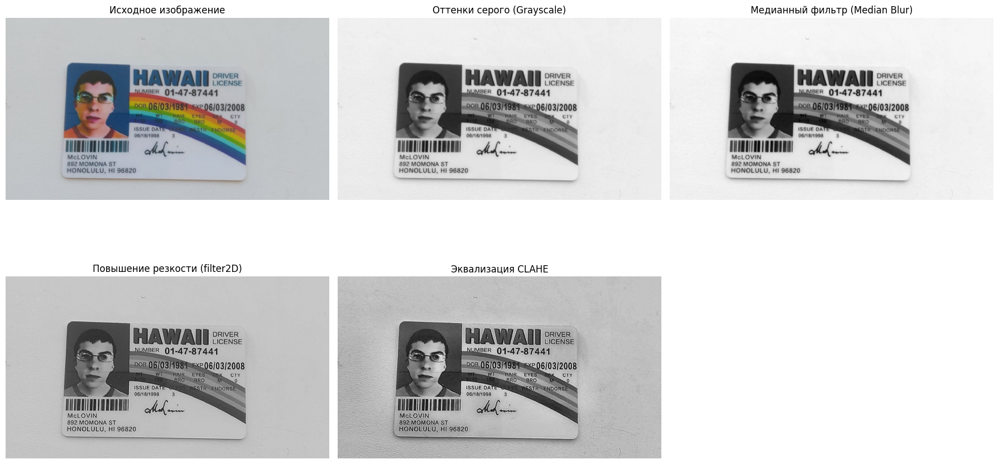

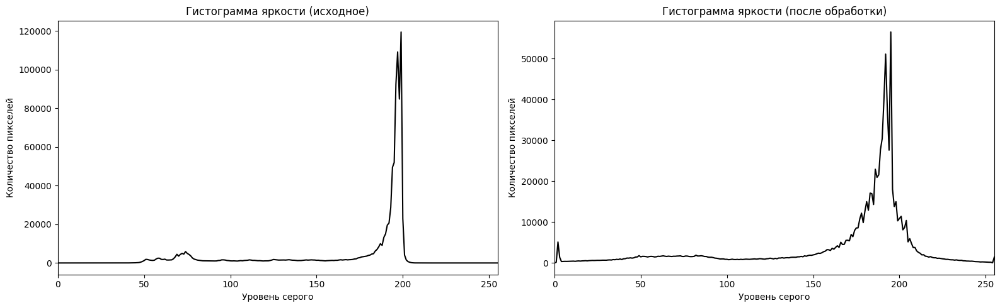

array([[195, 195, 195, ..., 195, 195, 195],
       [195, 195, 195, ..., 195, 195, 195],
       [195, 195, 195, ..., 195, 195, 195],
       ...,
       [139, 163, 177, ..., 186, 186, 186],
       [153, 177, 166, ..., 186, 186, 186],
       [206, 180, 172, ..., 186, 186, 186]], dtype=uint8)

In [53]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import requests

def optimize_scanned_document(image_matrix):
    #проверка входных данных: пустой ли массив, корректная ли размерность
    if image_matrix is None or not isinstance(image_matrix, np.ndarray):
        print('Ошибка: Входной объект пустой или не является массивом NumPy.')
        return
    if image_matrix.size == 0 or image_matrix.ndim not in (3, 2):
        print('Ошибка: Пустое изображение или неверная размерность.')
        return
    if image_matrix.ndim == 3 and image_matrix.shape[2] not in (3, 4):
        print('Ошибка: Допускаются изображения только с 1, 3 или 4 каналами.')
        return

    # Привожу изображение к трехканальному формату BGR при наличии альфа-канала или оттенков серого
    if image_matrix.ndim == 3 and image_matrix.shape[2] == 4:
        processed_matrix = cv2.cvtColor(image_matrix, cv2.COLOR_BGRA2BGR)
    elif image_matrix.ndim == 2:
        processed_matrix = cv2.cvtColor(image_matrix, cv2.COLOR_GRAY2BGR)
    else:
        processed_matrix = image_matrix.copy()

    # изображение в оттенки серого с помощью cv2.cvtColor()
    grayscale_version = cv2.cvtColor(processed_matrix, cv2.COLOR_BGR2GRAY)

    # медианный фильтр для удаления шумов с подходящим размером ядра
    median_smoothed = cv2.medianBlur(grayscale_version, 3)

    # ядро для повышения резкости (Unsharp Masking через фильтр свертки)
    sharpening_kernel = np.array([[-1, -1, -1],
                               [-1,  9, -1],
                               [-1, -1, -1]])

    # Применяю прямую свертку (cv2.filter2D) к размытому изображению для повышения четкости текста
    sharpened_picture = cv2.filter2D(median_smoothed, -1, sharpening_kernel)

    #метод CLAHE для улучшения контрастности деталей (clipLimit=2.0, tileGridSize=(8,8))
    clahe_object = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    contrast_enhanced_result = clahe_object.apply(sharpened_picture)

    # улучшенный результат на диск
    cv2.imwrite('dst_complex_task_1.jpg', contrast_enhanced_result)

    # список этапов обработки для визуализации (опциональный вывод промежуточных результатов)
    pipeline_stages = [
        (cv2.cvtColor(processed_matrix, cv2.COLOR_BGR2RGB), 'Исходное изображение', None),
        (grayscale_version, 'Оттенки серого (Grayscale)', 'gray'),
        (median_smoothed, 'Медианный фильтр (Median Blur)', 'gray'),
        (sharpened_picture, 'Повышение резкости (filter2D)', 'gray'),
        (contrast_enhanced_result, 'Эквализация CLAHE', 'gray')
    ]

    # Строю общую сетку визуализации промежуточных шагов
    plt.figure(figsize=(18, 10))
    for idx, (img_item, header_title, colormode) in enumerate(pipeline_stages, start=1):
        plt.subplot(2, 3, idx)
        if colormode:
            plt.imshow(img_item, cmap=colormode)
        else:
            plt.imshow(img_item)
        plt.title(header_title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

    # Строю гистограммы яркости исходного и обработанного изображений для сравнения
    orig_histogram = cv2.calcHist([grayscale_version], [0], None, [256], [0, 256])
    proc_histogram = cv2.calcHist([contrast_enhanced_result], [0], None, [256], [0, 256])

    plt.figure(figsize=(16, 5))

    plt.subplot(1, 2, 1)
    plt.plot(orig_histogram, color='black')
    plt.xlim([0, 255])
    plt.title('Гистограмма яркости (исходное)')
    plt.xlabel('Уровень серого')
    plt.ylabel('Количество пикселей')

    plt.subplot(1, 2, 2)
    plt.plot(proc_histogram, color='black')
    plt.xlim([0, 255])
    plt.title('Гистограмма яркости (после обработки)')
    plt.xlabel('Уровень серого')
    plt.ylabel('Количество пикселей')

    plt.tight_layout()
    plt.show()

    return contrast_enhanced_result

# Задаю новую ссылку на изображение для комплексного задания
DOCUMENT_URL = 'https://i.ytimg.com/vi/bifg1RdTBjo/maxresdefault.jpg'

# Скачиваю и декодирую изображение в исходном режиме (с поддержкой альфа-канала)
http_stream_resp = requests.get(DOCUMENT_URL, stream=True).raw
byte_array_buffer = np.asarray(bytearray(http_stream_resp.read()), dtype='uint8')
loaded_scan_image = cv2.imdecode(byte_array_buffer, cv2.IMREAD_UNCHANGED)

# Запускаю процедуру оптимизации скана
optimize_scanned_document(loaded_scan_image)

## **Дополнительное задание:**

- Поэкспериментируйте с параметрами медианного фильтра, ядром для фильтра повышения резкости и параметрами CLAHE для достижения наилучшего результата.
- Добавьте возможность передачи этих параметров в функцию `improve_scan` для более гибкой настройки обработки. **В качестве параметров по умолчанию установите те, которые показали себя лучше всего по результатам экспериментов**

**Пример с параметрами:**

```python
def improve_scan(image,
                 median_kernel_size=3,
                 sharp_kernel= np.array([[-1, -1, -1],
                                         [-1,  9, -1],
                                         [-1, -1, -1]]),
                 clahe_clip=2.0,
                 clahe_grid=(8,8),
                 visible=True):
    # Реализация с учетом переданных параметров
    ...
```


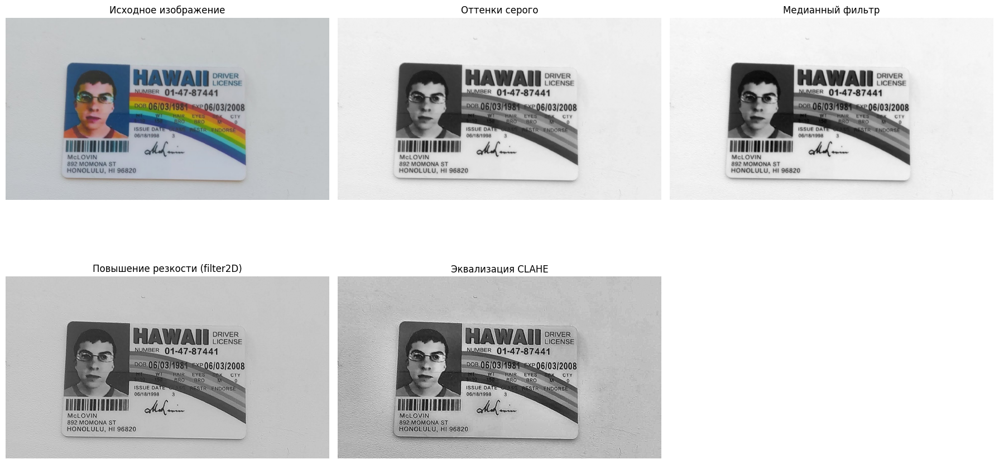

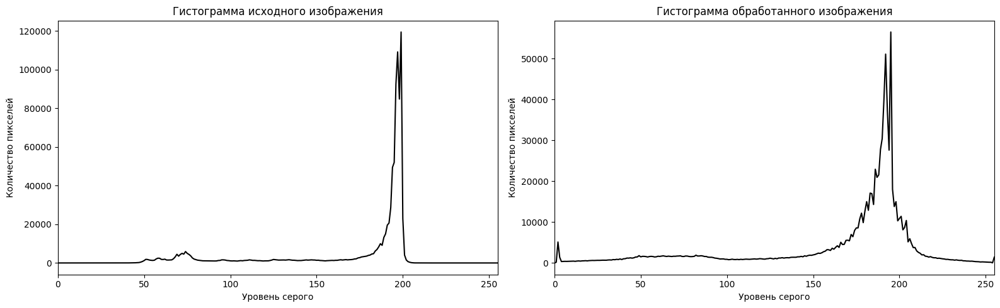

array([[195, 195, 195, ..., 195, 195, 195],
       [195, 195, 195, ..., 195, 195, 195],
       [195, 195, 195, ..., 195, 195, 195],
       ...,
       [139, 163, 177, ..., 186, 186, 186],
       [153, 177, 166, ..., 186, 186, 186],
       [206, 180, 172, ..., 186, 186, 186]], dtype=uint8)

In [54]:
def enhance_document_flexible(input_image_matrix,
                              median_kernel_dim=3,
                              custom_sharp_kernel=np.array([[-1, -1, -1],
                                                            [-1,  9, -1],
                                                            [-1, -1, -1]]),
                              clahe_clipping_limit=2.0,
                              clahe_grid_dimensions=(8, 8),
                              show_visuals=True):

    # пустой ли массив, корректна ли размерность
    if input_image_matrix is None or not isinstance(input_image_matrix, np.ndarray):
        print('Ошибка: Массив пустой или не является объектом NumPy.')
        return
    if input_image_matrix.size == 0 or input_image_matrix.ndim not in (3, 2):
        print('Ошибка: Пустое изображение либо неверная размерность.')
        return
    if input_image_matrix.ndim == 3 and input_image_matrix.shape[2] not in (3, 4):
        print('Ошибка: Допускаются изображения только с 1, 3 или 4 каналами.')
        return

    # изображение к трехканальному BGR при наличии альфа-канала или оттенков серого
    if input_image_matrix.ndim == 3 and input_image_matrix.shape[2] == 4:
        prepared_matrix = cv2.cvtColor(input_image_matrix, cv2.COLOR_BGRA2BGR)
    elif input_image_matrix.ndim == 2:
        prepared_matrix = cv2.cvtColor(input_image_matrix, cv2.COLOR_GRAY2BGR)
    else:
        prepared_matrix = input_image_matrix.copy()

    # оттенки серого (Grayscale)
    grayscale_layer = cv2.cvtColor(prepared_matrix, cv2.COLOR_BGR2GRAY)

    # медианный фильтр с переданным размером ядра
    median_filtered_layer = cv2.medianBlur(grayscale_layer, median_kernel_dim)

    # прямая свёртка (фильтр резкости)
    sharpened_layer = cv2.filter2D(median_filtered_layer, -1, custom_sharp_kernel)

    # метод CLAHE с заданными параметрами для улучшения контрастности
    clahe_processor = cv2.createCLAHE(clipLimit=clahe_clipping_limit, tileGridSize=clahe_grid_dimensions)
    clahe_result_layer = clahe_processor.apply(sharpened_layer)

    # итоговый результат обработки на диск
    cv2.imwrite('dst_additional_task.jpg', clahe_result_layer)

    # визуализация результатов преобразований, если флаг show_visuals активен
    if show_visuals:
        # список шагов обработки для вывода
        pipeline_collection = [
            (cv2.cvtColor(prepared_matrix, cv2.COLOR_BGR2RGB), 'Исходное изображение', None),
            (grayscale_layer, 'Оттенки серого', 'gray'),
            (median_filtered_layer, 'Медианный фильтр', 'gray'),
            (sharpened_layer, 'Повышение резкости (filter2D)', 'gray'),
            (clahe_result_layer, 'Эквализация CLAHE', 'gray')
        ]

        plt.figure(figsize=(18, 10))
        for step_idx, (img_frame, header_label, color_map_type) in enumerate(pipeline_collection, start=1):
            plt.subplot(2, 3, step_idx)
            if color_map_type:
                plt.imshow(img_frame, cmap=color_map_type)
            else:
                plt.imshow(img_frame)
            plt.title(header_label)
            plt.axis('off')
        plt.tight_layout()
        plt.show()

        # гистограммы яркости до и после обработки
        histogram_before = cv2.calcHist([grayscale_layer], [0], None, [256], [0, 256])
        histogram_after = cv2.calcHist([clahe_result_layer], [0], None, [256], [0, 256])

        plt.figure(figsize=(16, 5))

        plt.subplot(1, 2, 1)
        plt.plot(histogram_before, color='black')
        plt.xlim([0, 255])
        plt.title('Гистограмма исходного изображения')
        plt.xlabel('Уровень серого')
        plt.ylabel('Количество пикселей')

        plt.subplot(1, 2, 2)
        plt.plot(histogram_after, color='black')
        plt.xlim([0, 255])
        plt.title('Гистограмма обработанного изображения')
        plt.xlabel('Уровень серого')
        plt.ylabel('Количество пикселей')

        plt.tight_layout()
        plt.show()

    return clahe_result_layer

# новая ссылка на изображение для дополнительного задания
DOCUMENT_LINK = 'https://i.ytimg.com/vi/bifg1RdTBjo/maxresdefault.jpg'

# скачивание и декодирование изображения с сохранением исходной структуры
network_data_stream = requests.get(DOCUMENT_LINK, stream=True).raw
byte_buffer_array = np.asarray(bytearray(network_data_stream.read()), dtype='uint8')
loaded_source_image = cv2.imdecode(byte_buffer_array, cv2.IMREAD_UNCHANGED)

# функция с параметрами по умолчанию (или передаем кастомные при необходимости)
enhance_document_flexible(loaded_source_image)